# Exploring Unsupervised Learning with the Olivetti Faces Dataset

## Problem statement

Imagine we have a collection of face images, but we do not want to rely only on the person labels already attached to them. We want to understand whether machine-learning methods can discover groups of similar faces, represent the images in a simpler way, generate new face-like examples, and identify images that look unusual compared with the data the models learned from.

The practical challenge is that each image contains **4,096 pixel values**. Working with thousands of values makes the data difficult to explore directly. Different machine-learning techniques can help us look at the same dataset from different angles.

## What are we trying to achieve?

Using the Olivetti Faces dataset, this project explores five related goals:

1. **Discover groups of similar images:** Can K-Means group faces based on pixel similarity, without being given the person's identity?
2. **Create useful image features:** Can distances to K-Means cluster centers help a classifier predict which person is in an image?
3. **Simplify the data:** Can PCA reduce thousands of pixel features to a much smaller number while retaining most of the information?
4. **Learn how the data is distributed:** Can a Gaussian Mixture Model (GMM) learn patterns in the reduced data and generate new, synthetic face-like samples?
5. **Find unusual images:** Can GMM likelihood scores and PCA reconstruction errors help identify images that differ from the patterns learned by the models?

## Why are we using these algorithms?

| Technique | Why we use it in this project | The question it helps us answer |
|---|---|---|
| **K-Means clustering** | Groups images using similarity in their pixel values. | Which images look similar to one another? |
| **Logistic Regression** | Provides a supervised classification baseline using known person IDs. | How accurately can we predict the person in an image? |
| **K-Means distance features** | Represents each image by its distance from each cluster center. | Do these new features help classification? |
| **PCA** | Reduces 4,096 pixel features to fewer components while retaining most of the variance. | Can we represent the images more compactly? |
| **Gaussian Mixture Model (GMM)** | Learns a probability distribution over the PCA-reduced images and can generate samples. | What patterns does the model learn, and which images fit those patterns poorly? |
| **PCA reconstruction error** | Measures how different an image is from its reconstruction after dimensionality reduction. | Which images are harder for PCA to reconstruct? |

These methods do different jobs; they are not competing solutions to exactly the same problem. We compare their outputs to understand what each method can and cannot tell us.

## Dataset

The **Olivetti Faces** dataset contains 400 grayscale images from 40 people, with 10 images per person. Each image is 64 × 64 pixels, represented as 4,096 numerical pixel features.

We use the person IDs to evaluate clustering and train the classifier. K-Means and the GMM learn from the image features rather than using person IDs to form their groups or distributions.

## How the project is organized

We first load and prepare the data, then explore clustering and classification features, reduce the image dimensions, fit a probability model, and finally compare two approaches to identifying unusual images.

> **How to use this notebook:** Run the code cells in order in a Python/Jupyter environment. The explanations describe the purpose of each stage and how to interpret the results. The code and saved outputs from the original notebook have been retained.

In [1]:
%pip install scikit-learn


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\priya\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


## Setup and imports

Install scikit-learn if it is not already available in your Python environment. The following cells check the installed version and load the dataset.

In [1]:
import sklearn
print(sklearn.__version__)

1.9.1


## Load the Olivetti Faces dataset

The dataset contains **400 grayscale face images** from **40 people**, with 10 images per person. Each image is 64 × 64 pixels.

- `X` contains the flattened pixel values: 400 rows × 4,096 features.
- `y` contains the person ID for each image (0–39).

We keep `y` available to evaluate clustering and train a classifier later. K-Means itself will learn clusters from `X`, without using these person labels.

In [2]:
from sklearn.datasets import fetch_olivetti_faces

faces = fetch_olivetti_faces()

X = faces.data
y = faces.target

print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to C:\Users\priya\scikit_learn_data
Dataset shape: (400, 4096)
Labels shape: (400,)


## Split the data

We create three stratified subsets:
- **Training:** 60% (240 images)
- **Validation:** 20% (80 images)
- **Test:** 20% (80 images)

Stratification preserves the proportion of images from each person across the splits. The models are fitted on training data; validation data is used for comparisons. The test set should be kept for a final evaluation after model choices are complete.

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    stratify=y,
    random_state=42
)

In [5]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

In [6]:
print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (240, 4096)
Validation set: (80, 4096)
Test set: (80, 4096)


## Discovering groups of similar faces with K-Means

**What are we trying to find out?** We want to see whether K-Means can group face images that look similar, without using the person IDs to create those groups.

K-Means assigns each image to one of `K` clusters. Each cluster is represented by a **centroid** (the center of the group), and images are assigned to the nearest centroid.

We try different values of `K` and calculate the **Silhouette Score**. This score gives an indication of how well each image fits within its own cluster compared with nearby clusters. A higher score is generally better, but it does not guarantee that the groups correspond to real-world identities.

The next cells explore different values of `K` so we can compare the resulting scores.

In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = [2, 5, 10, 20, 30, 40, 50]

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_train)

    score = silhouette_score(X_train, cluster_labels)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.1433
K = 5, Silhouette Score = 0.0979
K = 10, Silhouette Score = 0.0953
K = 20, Silhouette Score = 0.1029
K = 30, Silhouette Score = 0.1190
K = 40, Silhouette Score = 0.1387
K = 50, Silhouette Score = 0.1598


In [8]:
k_values = [40, 50, 60, 70, 80, 90, 100]

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_train)

    score = silhouette_score(X_train, cluster_labels)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 40, Silhouette Score = 0.1387
K = 50, Silhouette Score = 0.1598
K = 60, Silhouette Score = 0.1783
K = 70, Silhouette Score = 0.1906
K = 80, Silhouette Score = 0.1942
K = 90, Silhouette Score = 0.2004
K = 100, Silhouette Score = 0.1967


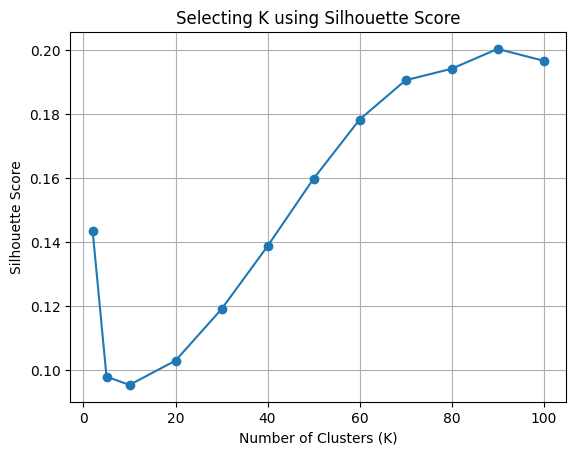

In [9]:
import matplotlib.pyplot as plt

k_values = [2, 5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100]

scores = [0.1433, 0.0979, 0.0953, 0.1029,
          0.1190, 0.1387, 0.1598, 0.1783,
          0.1906, 0.1942, 0.2004, 0.1967]

plt.plot(k_values, scores, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Selecting K using Silhouette Score")
plt.grid(True)
plt.show()

### Fitting K-Means and looking at the image groups

We use `K=90`, the highest Silhouette Score among the values tested in this experiment. This is the best value **among the tested values**, not proof of a global optimum.

The model is fitted only on `X_train`. Its cluster numbers are arbitrary group IDs; cluster 32 does not mean person 32. The visualizations help us inspect what kinds of images have been grouped together.

In [11]:
from sklearn.cluster import KMeans

# Create the K-Means model
kmeans = KMeans(
    n_clusters=90,
    random_state=42,
    n_init=10
)

# Train the model and assign cluster labels
train_clusters = kmeans.fit_predict(X_train)

print("Number of clusters:", len(set(train_clusters)))
print("Cluster assignments:", train_clusters[:20])

Number of clusters: 90
Cluster assignments: [32 35  1 32 25 12 28 13 32 17 17 83  5 47 25 43  2 48 37  6]


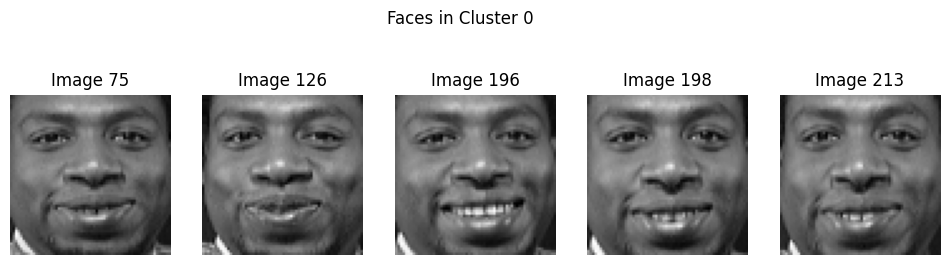

In [12]:
import matplotlib.pyplot as plt

cluster_id = 0

indices = [
    i for i, label in enumerate(train_clusters)
    if label == cluster_id
]

plt.figure(figsize=(12, 6))

for i, index in enumerate(indices[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[index].reshape(64, 64), cmap="gray")
    plt.axis("off")
    plt.title(f"Image {index}")

plt.suptitle(f"Faces in Cluster {cluster_id}")
plt.show()

In [10]:
import matplotlib.pyplot as plt

# Find images belonging to cluster 0
cluster_id = 0

# Get the positions of images in this cluster
indices = [
    i for i, label in enumerate(train_clusters)
    if label == cluster_id
]

# Display the images
plt.figure(figsize=(12, 6))

for i, index in enumerate(indices[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[index].reshape(64, 64), cmap="gray")
    plt.axis("off")
    plt.title(f"Image {index}")

plt.suptitle(f"Faces in Cluster {cluster_id}")
plt.show()

NameError: name 'train_clusters' is not defined

Images in cluster 32: 5


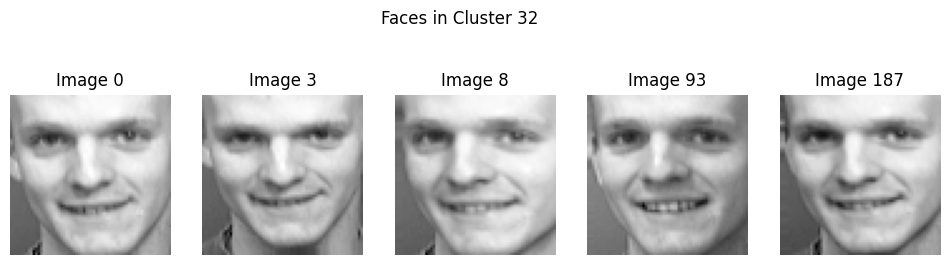

In [13]:
cluster_id = 32

indices = [
    i for i, label in enumerate(train_clusters)
    if label == cluster_id
]

print("Images in cluster 32:", len(indices))

plt.figure(figsize=(12, 6))

for i, index in enumerate(indices[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[index].reshape(64, 64), cmap="gray")
    plt.axis("off")
    plt.title(f"Image {index}")

plt.suptitle("Faces in Cluster 32")
plt.show()

Total clusters: 90
Total images: 240
Largest cluster: 7
Smallest cluster: 1


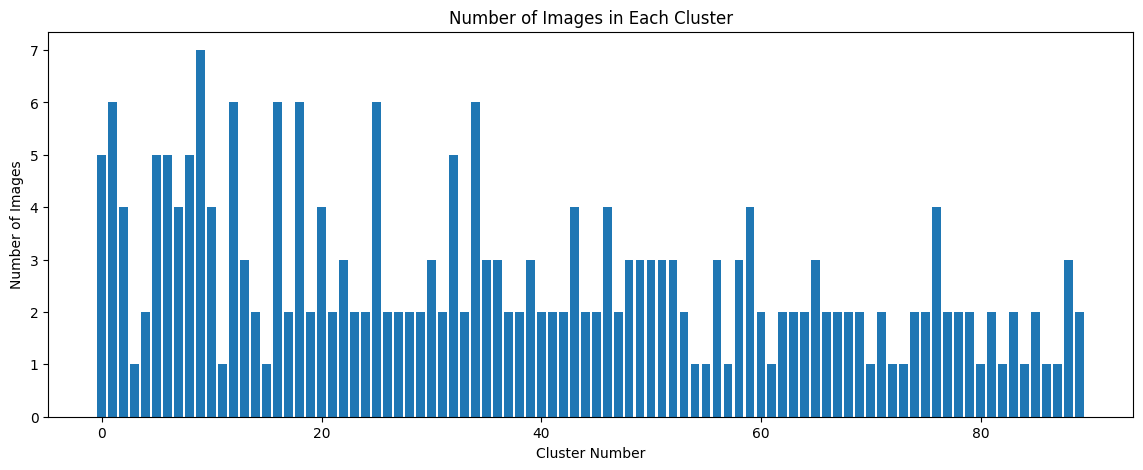

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Count images in each cluster
unique_clusters, counts = np.unique(
    train_clusters,
    return_counts=True
)

print("Total clusters:", len(unique_clusters))
print("Total images:", sum(counts))
print("Largest cluster:", max(counts))
print("Smallest cluster:", min(counts))

# Plot cluster sizes
plt.figure(figsize=(14, 5))
plt.bar(unique_clusters, counts)
plt.xlabel("Cluster Number")
plt.ylabel("Number of Images")
plt.title("Number of Images in Each Cluster")
plt.show()

In [15]:
import pandas as pd

# Create a table comparing actual person IDs and predicted clusters
comparison = pd.DataFrame({
    "Actual Person ID": y_train,
    "Predicted Cluster": train_clusters
})

# Display the first 20 images
print(comparison.head(20))


    Actual Person ID  Predicted Cluster
0                  4                 32
1                  2                 35
2                 24                  1
3                  4                 32
4                 17                 25
5                 29                 12
6                 13                 28
7                 32                 13
8                  4                 32
9                 33                 17
10                33                 17
11                39                 83
12                23                  5
13                 7                 47
14                17                 25
15                11                 43
16                14                  2
17                 6                 48
18                 9                 37
19                20                  6


In [16]:
# Count how many different people appear in each cluster

cluster_analysis = comparison.groupby(
    "Predicted Cluster"
)["Actual Person ID"].nunique()

print(cluster_analysis.sort_values(ascending=False).head(15))

Predicted Cluster
8     4
1     3
6     3
20    3
18    3
34    3
88    3
19    2
9     2
7     2
35    2
81    2
2     2
89    2
5     2
Name: Actual Person ID, dtype: int64


### Checking how well the clusters match the known person IDs

We use two complementary measures:

- **Adjusted Rand Index (ARI):** compares the learned cluster assignments with the known person IDs. A score of 1 means perfect agreement; values near 0 indicate agreement similar to random assignment. ARI is not classification accuracy.
- **Silhouette Score:** evaluates how well-separated the clusters are based on the feature distances.

We calculate these measures on training, validation, and test data. Because the validation and test sets are relatively small, interpret differences cautiously.

In [17]:
from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(y_train, train_clusters)

print("Adjusted Rand Index:", ari)

Adjusted Rand Index: 0.4896215939181686


In [18]:
# Assign validation images to existing clusters
val_clusters = kmeans.predict(X_val)

print("Validation images:", len(X_val))
print("Predicted cluster assignments:", val_clusters[:20])

Validation images: 80
Predicted cluster assignments: [86 62 10 72 18 40  1 34 82 60 36 76  6 67 21 65 66  3  2 79]


In [19]:
from sklearn.metrics import silhouette_score

val_silhouette = silhouette_score(X_val, val_clusters)

print("Validation Silhouette Score:", val_silhouette)

Validation Silhouette Score: 0.05426464229822159


In [20]:
from sklearn.metrics import adjusted_rand_score

val_ari = adjusted_rand_score(y_val, val_clusters)

print("Validation Adjusted Rand Index:", val_ari)

Validation Adjusted Rand Index: 0.36219724552794047


In [21]:
# Predict clusters for test images
test_clusters = kmeans.predict(X_test)

# Calculate test Silhouette Score
test_silhouette = silhouette_score(X_test, test_clusters)

# Calculate test ARI
test_ari = adjusted_rand_score(y_test, test_clusters)

print("Test Silhouette Score:", test_silhouette)
print("Test Adjusted Rand Index:", test_ari)

Test Silhouette Score: 0.10490689426660538
Test Adjusted Rand Index: 0.45118829981718467


## Testing whether K-Means features help identify a person

**What are we trying to find out?** Clustering groups similar images, but it does not directly predict a person's identity. In this stage, we test whether information produced by K-Means can help a supervised classifier predict the person in an image.

We first train **Logistic Regression** using all **4,096 original pixel features**. This gives us a baseline validation accuracy. We then compare it with models that use K-Means-derived distance features.

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Create the classifier
log_reg = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
log_reg.fit(X_train, y_train)

# Predict person IDs for validation images
y_pred = log_reg.predict(X_val)

# Calculate accuracy
accuracy = accuracy_score(y_val, y_pred)

print("Validation Accuracy:", accuracy)

Validation Accuracy: 0.95


### Representing each image by its distances to cluster centers

`KMeans.fit_transform()` fits K-Means on the training images and returns each image's distance to every cluster centroid. With 90 clusters, each image is represented by 90 distance features instead of 4,096 pixel features.

We call `transform()` on validation data so it uses the **same centroids learned from training data**. This avoids fitting a separate clustering model on the validation set.

In [23]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=90,
    random_state=42,
    n_init=10
)

X_train_reduced = kmeans.fit_transform(X_train)

X_val_reduced = kmeans.transform(X_val)

print("Original training shape:", X_train.shape)
print("Reduced training shape:", X_train_reduced.shape)

print("Original validation shape:", X_val.shape)
print("Reduced validation shape:", X_val_reduced.shape)

Original training shape: (240, 4096)
Reduced training shape: (240, 90)
Original validation shape: (80, 4096)
Reduced validation shape: (80, 90)


### Predicting identities using only the K-Means distance features

We train Logistic Regression using the 90 distance features and compare its validation accuracy with the original-feature baseline.

In [24]:
log_reg_reduced = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_reg_reduced.fit(X_train_reduced, y_train)

y_pred_reduced = log_reg_reduced.predict(X_val_reduced)

accuracy_reduced = accuracy_score(y_val, y_pred_reduced)

print("Validation Accuracy with reduced features:", accuracy_reduced)

Validation Accuracy with reduced features: 0.9375


### Combining the original pixels with K-Means distance features

We concatenate the original pixel features with the centroid-distance features. This tests whether the distance information adds useful information beyond the pixels.

In [25]:
import numpy as np

# Combine original and reduced training features
X_train_combined = np.hstack(
    (X_train, X_train_reduced)
)

# Combine original and reduced validation features
X_val_combined = np.hstack(
    (X_val, X_val_reduced)
)

print("Combined training shape:", X_train_combined.shape)
print("Combined validation shape:", X_val_combined.shape)

Combined training shape: (240, 4186)
Combined validation shape: (80, 4186)


In [26]:
log_reg_combined = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_reg_combined.fit(
    X_train_combined,
    y_train
)

y_pred_combined = log_reg_combined.predict(
    X_val_combined
)

accuracy_combined = accuracy_score(
    y_val,
    y_pred_combined
)

print("Validation Accuracy with combined features:",
      accuracy_combined)

Validation Accuracy with combined features: 0.95


### Comparing different numbers of clusters for the distance features

We repeat the reduced-feature experiment for several values of `K`. Each value creates a different number of distance features. We compare validation accuracy to identify the best result among the values tested.

In [27]:
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

k_values = [20, 40, 60, 80, 90, 100]

results = []

for k in k_values:

    # Create K-Means
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Reduce training and validation features
    X_train_reduced = kmeans.fit_transform(X_train)
    X_val_reduced = kmeans.transform(X_val)

    # Train Logistic Regression
    log_reg = LogisticRegression(
        max_iter=1000,
        random_state=42
    )

    log_reg.fit(X_train_reduced, y_train)

    # Predict validation images
    y_pred = log_reg.predict(X_val_reduced)

    # Calculate accuracy
    accuracy = accuracy_score(y_val, y_pred)

    results.append((k, accuracy))

    print(f"K={k}, Validation Accuracy={accuracy:.4f}")

K=20, Validation Accuracy=0.7375


K=40, Validation Accuracy=0.8750


K=60, Validation Accuracy=0.8875
K=80, Validation Accuracy=0.9250
K=90, Validation Accuracy=0.9375
K=100, Validation Accuracy=0.9000


### Finding a useful number of clusters for the combined features

We repeat the comparison after combining original pixels with K-Means distances. The validation set is used for this model comparison; the test set remains reserved for final evaluation.

In [28]:
k_values = [20, 40, 60, 80, 90, 100]

combined_results = []

for k in k_values:

    # Create K-Means
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Reduce training and validation data
    X_train_reduced = kmeans.fit_transform(X_train)
    X_val_reduced = kmeans.transform(X_val)

    # Combine original and reduced features
    X_train_combined = np.hstack((X_train, X_train_reduced))
    X_val_combined = np.hstack((X_val, X_val_reduced))

    # Train Logistic Regression
    log_reg = LogisticRegression(
        max_iter=3000,
        random_state=42
    )

    log_reg.fit(X_train_combined, y_train)

    # Predict and calculate accuracy
    y_pred = log_reg.predict(X_val_combined)
    accuracy = accuracy_score(y_val, y_pred)

    combined_results.append((k, accuracy))

    print(f"K={k}, Combined Validation Accuracy={accuracy:.4f}")

K=20, Combined Validation Accuracy=0.9625
K=40, Combined Validation Accuracy=0.9500
K=60, Combined Validation Accuracy=0.9500
K=80, Combined Validation Accuracy=0.9500
K=90, Combined Validation Accuracy=0.9500
K=100, Combined Validation Accuracy=0.9500


In [29]:
k_values = [20, 40, 60, 80, 90, 100]
results = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    X_train_reduced = kmeans.fit_transform(X_train)
    X_val_reduced = kmeans.transform(X_val)

    log_reg = LogisticRegression(
        max_iter=3000,
        random_state=42
    )

    log_reg.fit(X_train_reduced, y_train)

    y_pred = log_reg.predict(X_val_reduced)

    accuracy = accuracy_score(y_val, y_pred)
    results.append((k, accuracy))

    print(f"K={k}, Validation Accuracy={accuracy:.4f}")

K=20, Validation Accuracy=0.7250
K=40, Validation Accuracy=0.8625
K=60, Validation Accuracy=0.9125
K=80, Validation Accuracy=0.9250
K=90, Validation Accuracy=0.9375
K=100, Validation Accuracy=0.9000


## Reducing image complexity and learning the data distribution

**What are we trying to find out?** Each face image has 4,096 pixel features. We want to reduce this complexity while retaining most of the information, then explore whether a probability model can learn the patterns in the simplified data.

We start with **Principal Component Analysis (PCA)**. PCA transforms the original pixel features into a smaller set of principal components.

`n_components=0.99` asks PCA to retain enough components to explain at least 99% of the variance in the training data. PCA is fitted on training data and then reused to transform validation data.

In [30]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.99)

X_train_pca = pca.fit_transform(X_train)

print("Original shape:", X_train.shape)
print("Reduced shape:", X_train_pca.shape)
print("Number of components:", pca.n_components_)
print("Variance preserved:", sum(pca.explained_variance_ratio_))

Original shape: (240, 4096)
Reduced shape: (240, 177)
Number of components: 177
Variance preserved: 0.99023026


### Learning the distribution of the reduced face images with a GMM

A **Gaussian Mixture Model (GMM)** represents data as a combination of Gaussian probability distributions. Here, we fit 40 components to the PCA-transformed training images.

We chose 40 as an experimental starting point because the dataset contains 40 people. This does **not** mean that each Gaussian component corresponds to exactly one person.

In [31]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(
    n_components=40,
    covariance_type="full",
    random_state=42
)

gmm.fit(X_train_pca)

print("GMM training completed!")

GMM training completed!


### Generating new synthetic face-like samples

The fitted GMM can sample new points in the reduced PCA feature space. We then use PCA's inverse transformation to map those samples back into the original 4,096-feature image space.

These are synthetic samples generated by the model, not photographs of actual dataset participants. Their visual quality helps us inspect what the model has learned, but does not by itself prove that the model is accurate.

In [32]:
# Generate 10 new samples
X_generated, labels = gmm.sample(10)

print("Generated data shape:", X_generated.shape)
print("Generated component labels:", labels)

Generated data shape: (10, 177)
Generated component labels: [ 1  2  7  8 11 11 12 28 33 34]


In [33]:
# Convert generated PCA features back to original pixel features
X_generated_original = pca.inverse_transform(X_generated)

print("Generated images shape:", X_generated_original.shape)

Generated images shape: (10, 4096)


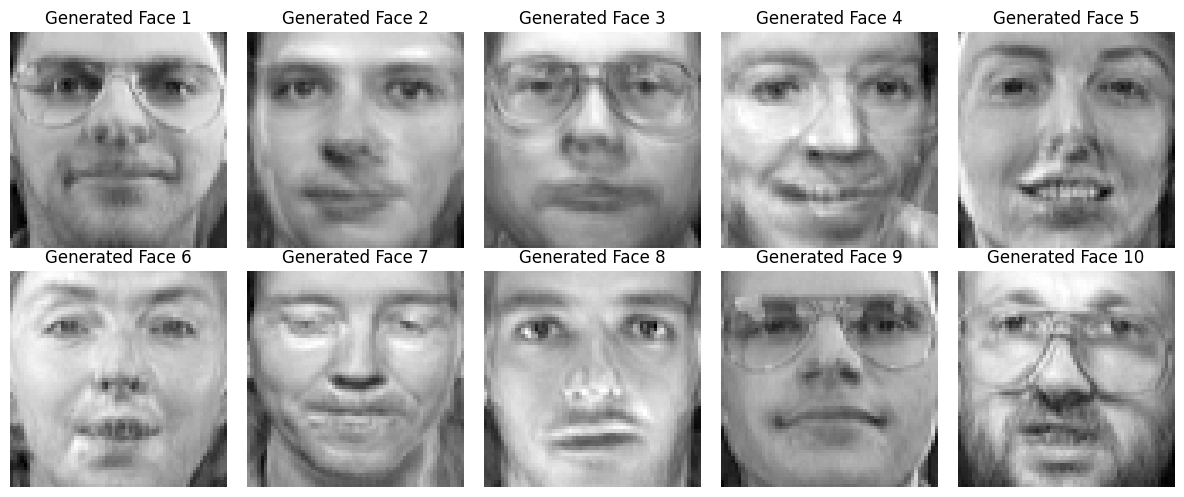

In [34]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image = X_generated_original[i].reshape(64, 64)
    ax.imshow(image, cmap="gray")
    ax.axis("off")
    ax.set_title(f"Generated Face {i+1}")

plt.tight_layout()
plt.show()

### Using GMM likelihood to assess how typical an image looks to the model

`score_samples()` returns a log-likelihood score for each image under the fitted GMM. A **lower (more negative) score** means the image is less likely under this model.

This score is not a calibrated probability of fraud or an anomaly label. It is a relative measure of how well the image fits the learned distribution.

In [35]:
# Calculate GMM scores for normal validation images
X_val_pca = pca.transform(X_val)

normal_scores = gmm.score_samples(X_val_pca)

print("First 10 normal image scores:")
print(normal_scores[:10])

First 10 normal image scores:
[-3.2301685e+06 -7.4555325e+06 -3.9238790e+06 -7.0894865e+06
 -1.0623041e+07 -4.6358710e+06 -1.3892446e+06 -7.0041725e+06
 -9.4709170e+06 -1.1355475e+07]


### Testing the GMM with altered images

We take one validation image and create darkened, flipped, and rotated versions. These controlled modifications let us observe how the GMM responds to images that differ from the examples it learned from.

The next cells transform the modified images using the same PCA model and compare their GMM log-likelihood scores.

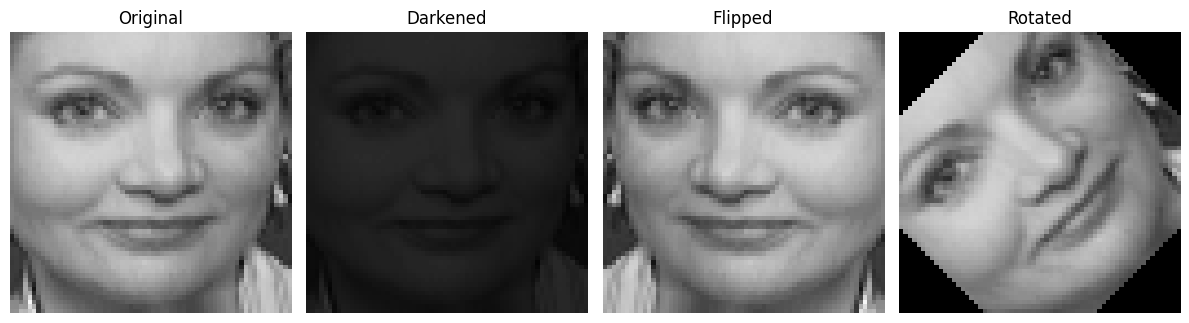

In [36]:
import numpy as np
from scipy.ndimage import rotate

# Select one validation image
original_image = X_val[0].reshape(64, 64)

# Create modified images
dark_image = original_image * 0.2
flipped_image = np.fliplr(original_image)
rotated_image = rotate(original_image, angle=45, reshape=False)

# Display all four images
fig, axes = plt.subplots(1, 4, figsize=(12, 4))

images = [
    original_image,
    dark_image,
    flipped_image,
    rotated_image
]

titles = ["Original", "Darkened", "Flipped", "Rotated"]

for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [37]:
# Convert modified images into flattened arrays
modified_images = np.array([
    original_image.flatten(),
    dark_image.flatten(),
    flipped_image.flatten(),
    rotated_image.flatten()
])

# Apply the same PCA transformation
modified_images_pca = pca.transform(modified_images)

# Calculate GMM scores
modified_scores = gmm.score_samples(modified_images_pca)

# Display results
for name, score in zip(titles, modified_scores):
    print(f"{name}: {score:.2f}")

Original: -3230168.50
Darkened: -91583984.00
Flipped: -17348540.00
Rotated: -71035784.00


## Checking unusual images using PCA reconstruction error

**What are we trying to find out?** GMM likelihood tells us how well an image fits the probability distribution learned by the GMM. Here, we use a different idea: if PCA compresses an image and then reconstructs it, how different is the reconstructed image from the original?

PCA can approximately reconstruct an image after reducing its dimensions. We transform validation images into principal-component space and then use `inverse_transform()` to reconstruct them.

Some detail may be lost because we retain 99% of the variance rather than every original dimension.

In [38]:
# Transform validation images into PCA features
X_val_pca = pca.transform(X_val)

# Reconstruct the original images
X_val_reconstructed = pca.inverse_transform(X_val_pca)

print("Original shape:", X_val.shape)
print("Reconstructed shape:", X_val_reconstructed.shape)

Original shape: (80, 4096)
Reconstructed shape: (80, 4096)


### Measuring the difference between original and reconstructed images

We calculate the **mean squared error (MSE)** between each original validation image and its PCA reconstruction. A larger error means the reconstruction differs more from the original image.

Reconstruction error is another way to identify unusual data, but it does not detect every kind of modification equally well.

In [39]:
# Calculate squared reconstruction error for each image
reconstruction_errors = np.mean(
    (X_val - X_val_reconstructed) ** 2,
    axis=1
)

print("First 10 reconstruction errors:")
print(reconstruction_errors[:10])

print("Average reconstruction error:",
      np.mean(reconstruction_errors))

First 10 reconstruction errors:
[0.00283801 0.00148456 0.00186257 0.00343143 0.00175215 0.00160144
 0.00089859 0.00137971 0.00292508 0.00271421]
Average reconstruction error: 0.0022540973


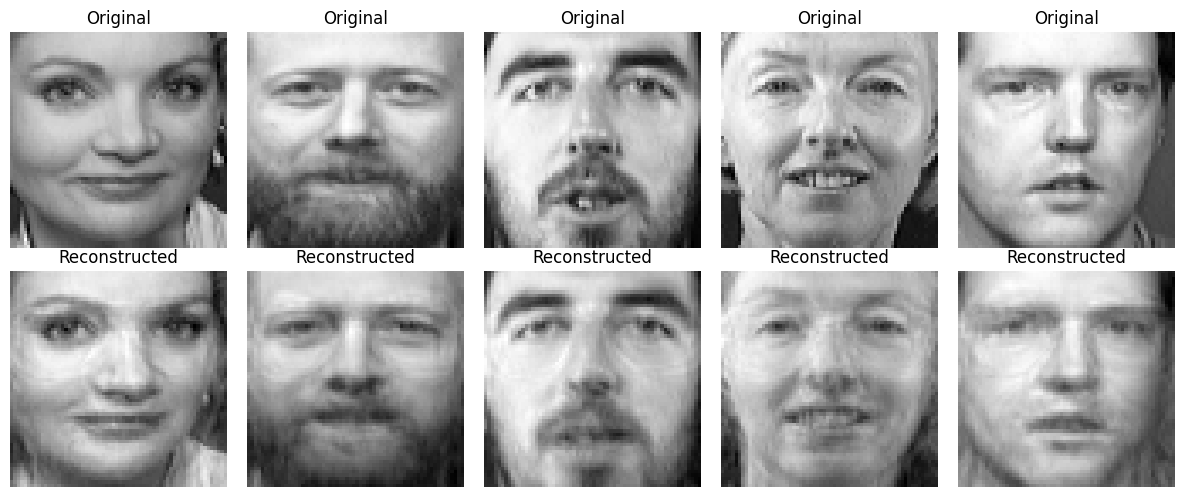

In [40]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i in range(5):
    # Original image
    axes[0, i].imshow(X_val[i].reshape(64, 64), cmap="gray")
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    # Reconstructed image
    axes[1, i].imshow(
        X_val_reconstructed[i].reshape(64, 64),
        cmap="gray"
    )
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

### Comparing reconstruction errors for altered images

Finally, we calculate PCA reconstruction error for the original, darkened, flipped, and rotated versions of the same image. Compare these values with the GMM scores from Exercise 12.

The two approaches measure different things:
- GMM score: how likely the image is under the learned probability distribution.
- PCA reconstruction error: how accurately the reduced representation can reconstruct the image.

In [41]:
# Transform modified images using PCA
modified_images_pca = pca.transform(modified_images)

# Reconstruct modified images
modified_images_reconstructed = pca.inverse_transform(
    modified_images_pca
)

# Calculate reconstruction error
modified_reconstruction_errors = np.mean(
    (modified_images - modified_images_reconstructed) ** 2,
    axis=1
)

# Display results
for name, error in zip(titles, modified_reconstruction_errors):
    print(f"{name}: {error:.6f}")

Original: 0.002838
Darkened: 0.001204
Flipped: 0.004027
Rotated: 0.017941


## What did we learn? — Results and key takeaways

### Main observations from these experiments

- **K-Means:** `K=90` produced the highest Silhouette Score among the values tested (0.2004). Cluster IDs are not the same as person IDs.
- **Classification:** Logistic Regression using original pixels achieved 95.00% validation accuracy. K-Means distance features alone achieved 93.75% at `K=90`. Combining original pixels with K-Means distances achieved 96.25% at `K=20`.
- **Interpret the difference carefully:** 96.25% is 77 correct predictions out of 80, compared with 76/80 for the 95.00% baseline. That is one additional correctly classified validation image, so it is a modest difference—not evidence of a guaranteed or robust improvement.
- **PCA:** 177 components retained approximately 99.02% of the training-data variance, reducing 4,096 features to 177.
- **GMM:** the model generated synthetic face-like samples and assigned lower log-likelihood scores to several modified images.
- **PCA reconstruction:** the rotated image had the largest reconstruction error in this experiment. The darkened image had a lower reconstruction error than the original, even though its GMM score was much lower.

### Important limitations

- These results come from one train/validation/test split and a limited set of hyperparameter values.
- The validation set contains only 80 images, so a one-image difference changes accuracy by 1.25 percentage points.
- Silhouette Score, ARI, GMM likelihood, and PCA reconstruction error measure different properties; none should be interpreted as a universal measure of model quality.
- An unusual score does not automatically mean an image is harmful or incorrect. Anomaly detection needs context and, in a real application, careful threshold selection and review.

### Final learning

This project demonstrates how unsupervised methods can reveal structure, create useful features, reduce dimensions, generate samples, and help flag unusual observations. It also shows why model results must be interpreted with appropriate metrics, validation, and limitations.